# Trabajo Final NLP — Clasificación de Géneros Cinematográficos
## `main3.ipynb` — Iteración 3: Técnicas Avanzadas

**Objetivo**: Multi-label classification de géneros a partir de sinopsis. Meta: micro F1 > 0.65

| Sección | Tema del Temario |
|---------|------------------|
| 2. Preprocesamiento | Tokenización, Lemmatización |
| 3. Representaciones | BoW, TF-IDF, Sentence Embeddings [S5] |
| 4. Modelos | NB, LR, SVM lineal [S4] |
| 5. Thresholds | Optimización por validación |
| 7. N-gramas | Perplejidad, Suavizado de Laplace [S3] |

In [10]:
%pip install torch

   ---------------------------------------- 0.0/114.6 MB ? eta -:--:--
    --------------------------------------- 1.8/114.6 MB 11.6 MB/s eta 0:00:10
   - -------------------------------------- 3.9/114.6 MB 10.6 MB/s eta 0:00:11
   - -------------------------------------- 5.2/114.6 MB 8.7 MB/s eta 0:00:13
   -- ------------------------------------- 7.3/114.6 MB 9.8 MB/s eta 0:00:11
   --- ------------------------------------ 10.0/114.6 MB 10.0 MB/s eta 0:00:11
   ---- ----------------------------------- 12.8/114.6 MB 10.6 MB/s eta 0:00:10
   ----- ---------------------------------- 14.4/114.6 MB 10.3 MB/s eta 0:00:10
   ----- ---------------------------------- 16.0/114.6 MB 9.9 MB/s eta 0:00:10
   ------ --------------------------------- 18.1/114.6 MB 9.8 MB/s eta 0:00:10
   ------ --------------------------------- 19.9/114.6 MB 9.8 MB/s eta 0:00:10
   ------- -------------------------------- 22.0/114.6 MB 9.8 MB/s eta 0:00:10
   -------- ------------------------------- 24.1/114.6 MB 9

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import math
import warnings
from collections import defaultdict, Counter
warnings.filterwarnings('ignore')

from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import classification_report, f1_score
from sklearn.preprocessing import StandardScaler

import torch
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'PyTorch {torch.__version__} | device: {device}')

SEED = 42
np.random.seed(SEED)

PyTorch 2.11.0+cpu | device: cpu


## 1. Carga y Exploración de Datos

In [12]:
train_df = pd.read_csv('../data/train.csv')
test_df  = pd.read_csv('../data/test.csv')

print(f'Train: {train_df.shape}  |  Test: {test_df.shape}')
print('Columnas train:', train_df.columns.tolist())
train_df.head(3)

Train: (8475, 3)  |  Test: (942, 2)
Columnas train: ['movie_name', 'genre', 'description']


,movie_name,genre,description
0,Silent Hill,"Horror, Mystery","Rose, a desperate mother takes her adopted dau..."
1,Breaking the Waves,"Drama, Romance","In a small and conservative Scottish village, ..."
2,Wind Chill,"Drama, Horror, Thriller",Two college students share a ride home for the...


Géneros únicos: 18
          genre  count
          Drama   3957
         Comedy   3046
       Thriller   2289
         Action   1974
        Romance   1483
      Adventure   1429
          Crime   1362
         Horror   1159
Science Fiction   1004
         Family    969
        Fantasy    962
        Mystery    813
      Animation    805
        History    442
            War    293
          Music    250
        Western    130
       TV Movie    101


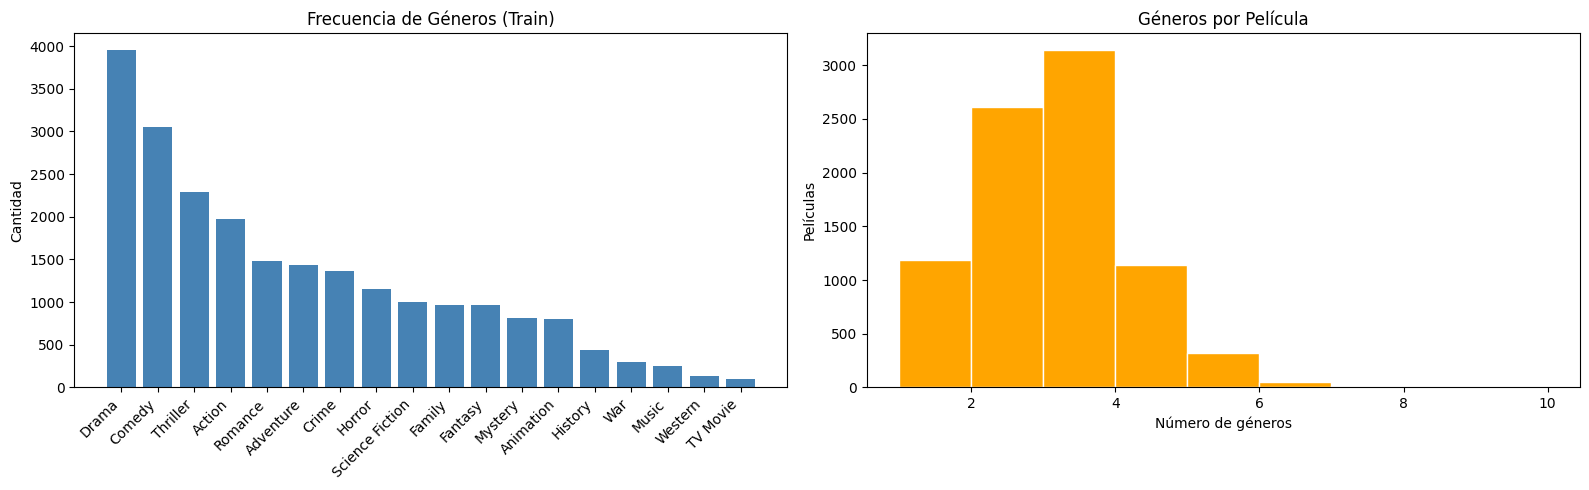


Longitud media descripción: 45 palabras | mediana: 41


In [13]:
# Parsear géneros (separados por ", ")
train_df['genre_list'] = train_df['genre'].apply(
    lambda x: [g.strip() for g in str(x).split(',')] if pd.notna(x) else []
)

all_genres = [g for gl in train_df['genre_list'] for g in gl]
genre_counts = Counter(all_genres)
genre_df = pd.DataFrame(genre_counts.items(), columns=['genre', 'count']).sort_values('count', ascending=False)

print(f'Géneros únicos: {len(genre_counts)}')
print(genre_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Distribución de géneros
axes[0].bar(genre_df['genre'], genre_df['count'], color='steelblue')
axes[0].set_xticklabels(genre_df['genre'], rotation=45, ha='right')
axes[0].set_title('Frecuencia de Géneros (Train)')
axes[0].set_ylabel('Cantidad')

# Géneros por película
n_genres = train_df['genre_list'].apply(len)
axes[1].hist(n_genres, bins=range(1, n_genres.max()+2), color='orange', edgecolor='white')
axes[1].set_title('Géneros por Película')
axes[1].set_xlabel('Número de géneros')
axes[1].set_ylabel('Películas')

plt.tight_layout()
plt.show()

desc_len = train_df['description'].fillna('').apply(lambda x: len(x.split()))
print(f'\nLongitud media descripción: {desc_len.mean():.0f} palabras | mediana: {desc_len.median():.0f}')

## 2. Preprocesamiento NLP [S4, S5]

Aplicamos preprocesamiento con **spaCy** (`en_core_web_sm`):
- **Lemmatización**: reduce palabras a su forma base (`running → run`)
- **Eliminación de stopwords** y puntuación
- Filtrado de tokens cortos (<3 caracteres)

Si spaCy no está disponible, se usa preprocesamiento básico con regex.

In [14]:
try:
    import spacy
    nlp_spacy = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
    SPACY_AVAILABLE = True
    print('spaCy cargado: en_core_web_sm')
except Exception as e:
    print(f'spaCy no disponible ({e}). Usando preprocesamiento básico.')
    SPACY_AVAILABLE = False


def basic_clean(text):
    if pd.isna(text):
        return ''
    text = str(text).lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()


def spacy_clean(texts, batch_size=256):
    result = []
    texts = [str(t) if pd.notna(t) else '' for t in texts]
    for doc in nlp_spacy.pipe(texts, batch_size=batch_size):
        tokens = [
            token.lemma_.lower() for token in doc
            if not token.is_stop and not token.is_punct
            and token.is_alpha and len(token.text) > 2
        ]
        result.append(' '.join(tokens))
    return result


print('Preprocesando textos...')
all_desc = pd.concat([train_df['description'], test_df['description']]).tolist()

if SPACY_AVAILABLE:
    all_clean = spacy_clean(all_desc)
else:
    all_clean = [basic_clean(t) for t in all_desc]

train_df['text_clean'] = all_clean[:len(train_df)]
test_df['text_clean']  = all_clean[len(train_df):]

print('Listo.')
print(f'  Original: {train_df["description"].iloc[0][:120]}')
print(f'  Limpio:   {train_df["text_clean"].iloc[0][:120]}')

spaCy no disponible (No module named 'spacy'). Usando preprocesamiento básico.
Preprocesando textos...
Listo.
  Original: Rose, a desperate mother takes her adopted daughter, Sharon, to the town of Silent Hill in an attempt to cure her of her
  Limpio:   rose a desperate mother takes her adopted daughter sharon to the town of silent hill in an attempt to cure her of her ai


## 3. Representación de Textos [S5]

| Representación | Tipo | Descripción |
|---|---|---|
| BoW | Dispersa | Conteo de palabras, `CountVectorizer` |
| TF-IDF + bigramas | Dispersa | Pondera términos raros, captura co-ocurrencias |
| Sentence Embeddings | Densa/Contextual | `all-MiniLM-L6-v2` via sentence-transformers |

In [15]:
# Split ANTES de ajustar vectorizadores para evitar data leakage
X_raw = train_df['text_clean'].values
y_raw = train_df['genre_list'].values

X_tr_raw, X_val_raw, y_tr_raw, y_val_raw = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=SEED
)
print(f'Train: {len(X_tr_raw)} | Val: {len(X_val_raw)}')

# MultiLabelBinarizer [S4 - codificación multi-etiqueta]
mlb = MultiLabelBinarizer()
y_train = mlb.fit_transform(y_tr_raw)
y_val   = mlb.transform(y_val_raw)
print(f'Clases ({len(mlb.classes_)}): {mlb.classes_.tolist()}')

# BoW — baseline [S5: representación dispersa]
bow_vec = CountVectorizer(max_features=10000, stop_words='english', min_df=2)
X_tr_bow  = bow_vec.fit_transform(X_tr_raw)
X_val_bow = bow_vec.transform(X_val_raw)
print(f'\nBoW shape:   {X_tr_bow.shape}')

# TF-IDF con bigramas [S5: TF-IDF, ngrams]
tfidf_vec = TfidfVectorizer(
    max_features=20000, ngram_range=(1, 2),
    stop_words='english', min_df=2, sublinear_tf=True
)
X_tr_tfidf  = tfidf_vec.fit_transform(X_tr_raw)
X_val_tfidf = tfidf_vec.transform(X_val_raw)
print(f'TF-IDF shape: {X_tr_tfidf.shape}')

Train: 6780 | Val: 1695
Clases (18): ['Action', 'Adventure', 'Animation', 'Comedy', 'Crime', 'Drama', 'Family', 'Fantasy', 'History', 'Horror', 'Music', 'Mystery', 'Romance', 'Science Fiction', 'TV Movie', 'Thriller', 'War', 'Western']

BoW shape:   (6780, 10000)
TF-IDF shape: (6780, 20000)


In [16]:
# Sentence Embeddings [S5: Embeddings Contextuales, S6: Transformers]
# Modelo all-MiniLM-L6-v2: ligero (~80MB), 384 dims, muy buena calidad
try:
    from sentence_transformers import SentenceTransformer
    print('Cargando sentence-transformers (all-MiniLM-L6-v2)...')
    st_model = SentenceTransformer('all-MiniLM-L6-v2')

    print('Codificando train...')
    X_tr_emb = st_model.encode(
        X_tr_raw.tolist(), batch_size=64,
        show_progress_bar=True, convert_to_numpy=True
    )
    print('Codificando val...')
    X_val_emb = st_model.encode(
        X_val_raw.tolist(), batch_size=64,
        show_progress_bar=True, convert_to_numpy=True
    )
    scaler = StandardScaler()
    X_tr_emb_s  = scaler.fit_transform(X_tr_emb)
    X_val_emb_s = scaler.transform(X_val_emb)

    EMB_AVAILABLE = True
    print(f'Embeddings: {X_tr_emb_s.shape}')
except ImportError:
    print('sentence-transformers no instalado. Saltando embeddings contextuales.')
    EMB_AVAILABLE = False

sentence-transformers no instalado. Saltando embeddings contextuales.


## 4. Modelos de Clasificación [S4]

Estrategia **One-vs-Rest (OvR)**: para cada género, se entrena un clasificador binario independiente. Permite asignar múltiples etiquetas.

Para SVM usamos `decision_function` + sigmoide como proxy de probabilidad, ya que `LinearSVC` no implementa `predict_proba` nativamente.

In [17]:
results = {}  # registro de métricas para comparación final


def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))


def apply_threshold(y_prob, threshold):
    y_pred = (y_prob >= threshold).astype(int)
    # garantizar al menos un género por película
    for i in range(len(y_pred)):
        if y_pred[i].sum() == 0:
            y_pred[i, y_prob[i].argmax()] = 1
    return y_pred


def evaluate(name, y_true, y_prob, threshold=0.5):
    y_pred = apply_threshold(y_prob, threshold)
    print(f'\n{"="*60}')
    print(f'  {name}  (threshold={threshold:.2f})')
    print(f'{"="*60}')
    print(classification_report(
        y_true, y_pred, target_names=mlb.classes_, zero_division=0
    ))
    rep = classification_report(
        y_true, y_pred, target_names=mlb.classes_,
        output_dict=True, zero_division=0
    )
    results[name] = {
        'micro_f1':    rep['micro avg']['f1-score'],
        'macro_f1':    rep['macro avg']['f1-score'],
        'samples_f1':  rep.get('samples avg', {}).get('f1-score', 0),
        'precision':   rep['micro avg']['precision'],
        'recall':      rep['micro avg']['recall'],
        'threshold':   threshold,
    }
    return y_pred

In [18]:
# --- Modelo 1: Naïve Bayes Multinomial [S4] ---
# Modelo probabilístico generativo basado en P(word|class)
print('Entrenando Naïve Bayes...')
nb_clf = OneVsRestClassifier(MultinomialNB(alpha=0.1))
nb_clf.fit(X_tr_bow, y_train)

y_prob_nb = nb_clf.predict_proba(X_val_bow)
evaluate('Naïve Bayes (BoW)', y_val, y_prob_nb, threshold=0.25)

Entrenando Naïve Bayes...

  Naïve Bayes (BoW)  (threshold=0.25)
                 precision    recall  f1-score   support

         Action       0.64      0.74      0.69       411
      Adventure       0.50      0.59      0.55       278
      Animation       0.53      0.48      0.50       172
         Comedy       0.65      0.75      0.69       625
          Crime       0.57      0.64      0.60       273
          Drama       0.62      0.74      0.68       789
         Family       0.61      0.56      0.58       178
        Fantasy       0.43      0.42      0.43       189
        History       0.45      0.38      0.41        90
         Horror       0.57      0.58      0.58       231
          Music       0.55      0.40      0.46        53
        Mystery       0.41      0.41      0.41       163
        Romance       0.46      0.60      0.52       268
Science Fiction       0.64      0.66      0.65       213
       TV Movie       0.00      0.00      0.00        17
       Thriller       

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [1, 1, 1, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 1, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [1, 1, 0, ..., 1, 0, 0]], shape=(1695, 18))

In [19]:
# --- Modelo 2: Regresión Logística con TF-IDF [S4] ---
# Clasificador discriminativo lineal con regularización L2
print('Entrenando Logistic Regression (TF-IDF)...')
lr_clf = OneVsRestClassifier(
    LogisticRegression(C=1.0, max_iter=1000, solver='lbfgs', random_state=SEED)
)
lr_clf.fit(X_tr_tfidf, y_train)

y_prob_lr = lr_clf.predict_proba(X_val_tfidf)
evaluate('LR (TF-IDF bigrams)', y_val, y_prob_lr, threshold=0.35)

Entrenando Logistic Regression (TF-IDF)...

  LR (TF-IDF bigrams)  (threshold=0.35)
                 precision    recall  f1-score   support

         Action       0.74      0.62      0.68       411
      Adventure       0.61      0.30      0.40       278
      Animation       0.91      0.06      0.11       172
         Comedy       0.61      0.77      0.68       625
          Crime       0.76      0.39      0.51       273
          Drama       0.57      0.91      0.70       789
         Family       0.85      0.16      0.27       178
        Fantasy       0.64      0.08      0.15       189
        History       0.00      0.00      0.00        90
         Horror       0.77      0.26      0.39       231
          Music       0.00      0.00      0.00        53
        Mystery       0.79      0.07      0.12       163
        Romance       0.66      0.38      0.49       268
Science Fiction       0.86      0.32      0.47       213
       TV Movie       0.00      0.00      0.00        17
   

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 1, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(1695, 18))

In [20]:
# --- Modelo 3: SVM Lineal con TF-IDF [S4] ---
# Maximiza el margen entre clases; típicamente supera LR en clasificación de texto
# decision_function → sigmoide como proxy de probabilidad para threshold tuning
print('Entrenando SVM Lineal (TF-IDF)...')
svm_clf = OneVsRestClassifier(
    LinearSVC(C=0.5, max_iter=5000, class_weight='balanced', random_state=SEED)
)
svm_clf.fit(X_tr_tfidf, y_train)

df_svm       = svm_clf.decision_function(X_val_tfidf)  # distancias signadas
y_prob_svm   = sigmoid(df_svm)
evaluate('SVM Lineal (TF-IDF)', y_val, y_prob_svm, threshold=0.5)

Entrenando SVM Lineal (TF-IDF)...

  SVM Lineal (TF-IDF)  (threshold=0.50)
                 precision    recall  f1-score   support

         Action       0.68      0.71      0.69       411
      Adventure       0.52      0.58      0.55       278
      Animation       0.66      0.47      0.54       172
         Comedy       0.65      0.65      0.65       625
          Crime       0.59      0.61      0.60       273
          Drama       0.67      0.68      0.68       789
         Family       0.62      0.54      0.58       178
        Fantasy       0.49      0.42      0.45       189
        History       0.43      0.29      0.34        90
         Horror       0.61      0.58      0.59       231
          Music       0.71      0.45      0.55        53
        Mystery       0.42      0.40      0.41       163
        Romance       0.50      0.57      0.53       268
Science Fiction       0.63      0.59      0.61       213
       TV Movie       0.00      0.00      0.00        17
       Thril

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 1, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 1, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 1, 0, ..., 1, 0, 0]], shape=(1695, 18))

In [21]:
# --- Modelo 4: SVM sobre Sentence Embeddings [S5, S6] ---
# Combina representación contextual densa con la robustez de SVM
if EMB_AVAILABLE:
    print('Entrenando SVM (Sentence Embeddings)...')
    svm_emb_clf = OneVsRestClassifier(
        LinearSVC(C=1.0, max_iter=5000, class_weight='balanced', random_state=SEED)
    )
    svm_emb_clf.fit(X_tr_emb_s, y_train)

    df_emb       = svm_emb_clf.decision_function(X_val_emb_s)
    y_prob_emb   = sigmoid(df_emb)
    evaluate('SVM (Sentence Embeddings)', y_val, y_prob_emb, threshold=0.5)
else:
    print('Sentence Embeddings no disponibles. Saltando Modelo 4.')

Sentence Embeddings no disponibles. Saltando Modelo 4.


## 5. Optimización de Thresholds

Un threshold único puede no ser óptimo para todos los géneros. Buscamos el **threshold global** que maximiza el **micro F1** en validación.

Esta búsqueda es posible solo en validación — nunca en test — para evitar sobreajuste.

--- SVM TF-IDF ---


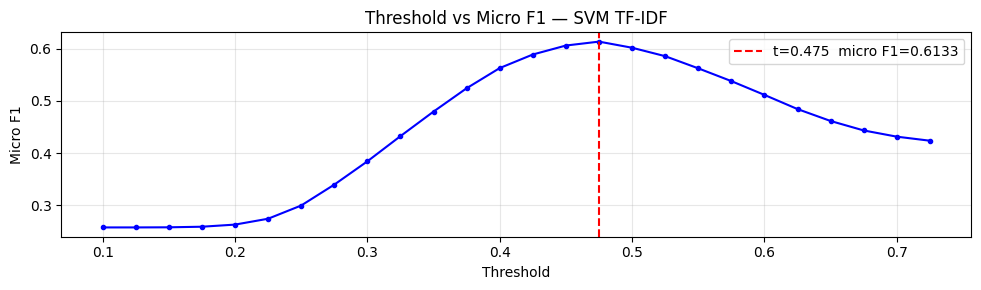

  Mejor threshold: 0.475  |  micro F1 = 0.6133

  SVM TF-IDF (opt threshold)  (threshold=0.47)
                 precision    recall  f1-score   support

         Action       0.64      0.78      0.71       411
      Adventure       0.48      0.63      0.54       278
      Animation       0.57      0.53      0.55       172
         Comedy       0.63      0.74      0.68       625
          Crime       0.54      0.67      0.60       273
          Drama       0.65      0.75      0.69       789
         Family       0.54      0.61      0.57       178
        Fantasy       0.43      0.48      0.46       189
        History       0.34      0.33      0.34        90
         Horror       0.56      0.66      0.61       231
          Music       0.62      0.53      0.57        53
        Mystery       0.39      0.48      0.43       163
        Romance       0.45      0.66      0.54       268
Science Fiction       0.59      0.67      0.63       213
       TV Movie       0.00      0.00      0.00   

In [22]:
def optimize_threshold(y_prob, y_true, name):
    thresholds = np.arange(0.10, 0.75, 0.025)
    scores = []
    best_t, best_f1 = 0.5, 0.0

    for t in thresholds:
        y_pred = apply_threshold(y_prob, t)
        f1 = f1_score(y_true, y_pred, average='micro', zero_division=0)
        scores.append(f1)
        if f1 > best_f1:
            best_f1, best_t = f1, t

    plt.figure(figsize=(10, 3))
    plt.plot(thresholds, scores, 'b-o', markersize=3)
    plt.axvline(best_t, color='r', linestyle='--',
                label=f't={best_t:.3f}  micro F1={best_f1:.4f}')
    plt.xlabel('Threshold')
    plt.ylabel('Micro F1')
    plt.title(f'Threshold vs Micro F1 — {name}')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
    print(f'  Mejor threshold: {best_t:.3f}  |  micro F1 = {best_f1:.4f}')
    return best_t


print('--- SVM TF-IDF ---')
best_t_svm = optimize_threshold(y_prob_svm, y_val, 'SVM TF-IDF')
evaluate('SVM TF-IDF (opt threshold)', y_val, y_prob_svm, threshold=best_t_svm)

if EMB_AVAILABLE:
    print('\n--- SVM Sentence Embeddings ---')
    best_t_emb = optimize_threshold(y_prob_emb, y_val, 'SVM Embeddings')
    evaluate('SVM Embeddings (opt threshold)', y_val, y_prob_emb, threshold=best_t_emb)
else:
    best_t_emb = 0.5

## 6. Comparación de Modelos

TABLA COMPARATIVA — VALIDACIÓN (80/20 split)
                            micro_f1  macro_f1  samples_f1  precision  recall  threshold
SVM TF-IDF (opt threshold)    0.6133    0.5334      0.6041     0.5656  0.6698      0.475
Naïve Bayes (BoW)             0.6088    0.5244      0.5990     0.5796  0.6412      0.250
SVM Lineal (TF-IDF)           0.6016    0.5202      0.5906     0.6072  0.5961      0.500
LR (TF-IDF bigrams)           0.5560    0.3203      0.5534     0.6368  0.4935      0.350

Baseline previo (iteraciones 0-2):
  NB  (BoW 5k)              micro F1 = 0.60
  LR  (TF-IDF bigrams, C=2) micro F1 = 0.55

Mejor modelo: SVM TF-IDF (opt threshold)  micro F1 = 0.6133


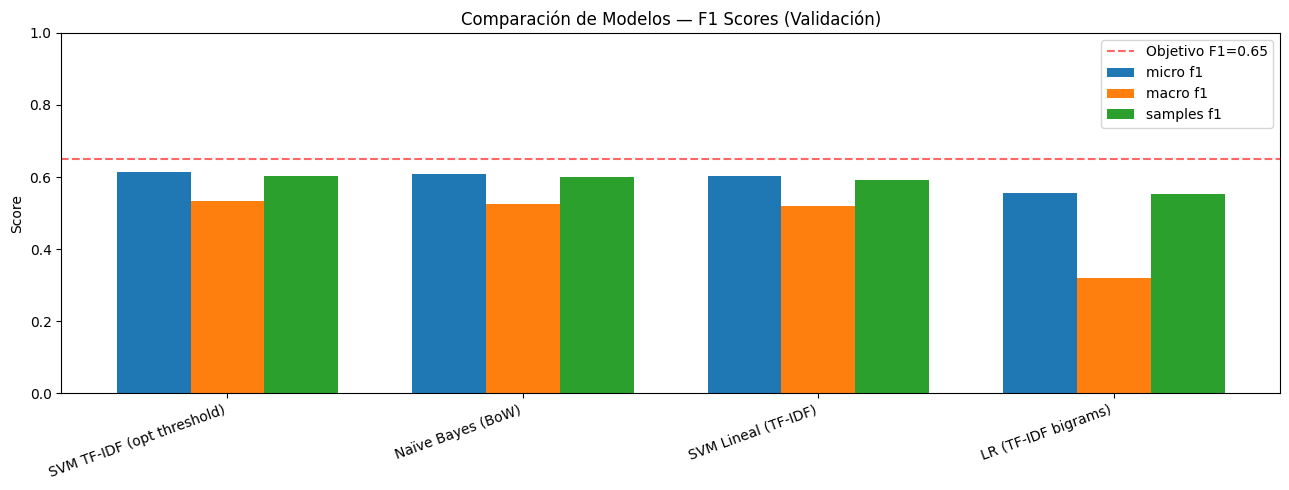

In [23]:
cmp = pd.DataFrame(results).T.sort_values('micro_f1', ascending=False).round(4)

print('='*65)
print('TABLA COMPARATIVA — VALIDACIÓN (80/20 split)')
print('='*65)
print(cmp[['micro_f1','macro_f1','samples_f1','precision','recall','threshold']].to_string())
print()
print('Baseline previo (iteraciones 0-2):')
print('  NB  (BoW 5k)              micro F1 = 0.60')
print('  LR  (TF-IDF bigrams, C=2) micro F1 = 0.55')
best_name = cmp.index[0]
print(f'\nMejor modelo: {best_name}  micro F1 = {cmp["micro_f1"].iloc[0]:.4f}')

# Gráfico comparativo
fig, ax = plt.subplots(figsize=(13, 5))
x = np.arange(len(cmp))
w = 0.25
for i, col in enumerate(['micro_f1', 'macro_f1', 'samples_f1']):
    ax.bar(x + i*w, cmp[col], w, label=col.replace('_', ' '))
ax.axhline(0.65, color='red', linestyle='--', alpha=0.6, label='Objetivo F1=0.65')
ax.set_xticks(x + w)
ax.set_xticklabels(cmp.index, rotation=20, ha='right')
ax.set_ylabel('Score')
ax.set_ylim(0, 1)
ax.set_title('Comparación de Modelos — F1 Scores (Validación)')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Análisis de Perplejidad con Modelo de N-Gramas [S3]

La **perplejidad** mide cuán bien un modelo de lenguaje predice un texto nuevo:

$$PP(W) = P(w_1 w_2 \ldots w_N)^{-1/N}$$

Menor perplejidad = mejor modelo. Implementamos un modelo de **bigramas con Suavizado de Laplace** [S3]:

$$P(w_i | w_{i-1}) = \frac{C(w_{i-1}, w_i) + \alpha}{C(w_{i-1}) + \alpha \cdot |V|}$$

In [24]:
class BigramLM:
    """Modelo de bigramas con suavizado de Laplace [S3]."""

    def __init__(self, alpha=0.1):
        self.alpha = alpha
        self.bigram  = defaultdict(lambda: defaultdict(int))
        self.unigram = defaultdict(int)
        self.vocab   = set()

    def train(self, texts):
        for text in texts:
            toks = ['<s>'] + text.lower().split()[:100] + ['</s>']  # cap 100 tokens/doc
            for t in toks:
                self.vocab.add(t)
            for a, b in zip(toks, toks[1:]):
                self.bigram[a][b]  += 1
                self.unigram[a]    += 1
        print(f'Vocab: {len(self.vocab):,} | bigram contexts: {len(self.bigram):,}')

    def log_prob(self, w1, w2):
        V = len(self.vocab)
        num = self.bigram[w1][w2] + self.alpha
        den = self.unigram[w1]    + self.alpha * V
        return math.log(num / den)

    def perplexity(self, text):
        toks = ['<s>'] + text.lower().split()[:100] + ['</s>']
        N = len(toks) - 1
        if N < 1:
            return float('inf')
        lp = sum(self.log_prob(toks[i], toks[i+1]) for i in range(N))
        return math.exp(-lp / N)


print('Entrenando modelo de bigramas...')
lm = BigramLM(alpha=0.1)
lm.train(X_tr_raw.tolist())

# Perplejidad en primeras 500 muestras de val para rapidez
perp_sample = [lm.perplexity(t) for t in X_val_raw[:500]]
perp_finite = [p for p in perp_sample if p < 1e6]

print(f'\nPerplejidad (bigramas + Laplace α=0.1) sobre val[:500]:')
print(f'  Media:   {np.mean(perp_finite):.1f}')
print(f'  Mediana: {np.median(perp_finite):.1f}')

# ¿Varía la perplejidad entre géneros? (textos de acción vs drama)
genre_perp = {}
for g in ['Drama', 'Action', 'Comedy', 'Horror', 'Romance']:
    idx = [i for i, glist in enumerate(y_val_raw[:500]) if g in glist]
    if idx:
        vals = [perp_sample[i] for i in idx if perp_sample[i] < 1e6]
        if vals:
            genre_perp[g] = np.mean(vals)

print('\nPerplejidad media por género:')
for g, p in sorted(genre_perp.items(), key=lambda x: x[1]):
    print(f'  {g:<12}: {p:.1f}')

# Comparar bigramas vs unigramas para mostrar mejora
# Unigrama: P(w) = C(w)/N  (sin contexto)
unigram_counts = Counter(' '.join(X_tr_raw.tolist()).split())
total_tokens   = sum(unigram_counts.values())

def unigram_perplexity(text):
    toks = text.lower().split()[:100]
    if not toks:
        return float('inf')
    V = len(unigram_counts)
    lp = sum(math.log((unigram_counts.get(w, 0) + 0.1) / (total_tokens + 0.1*V))
             for w in toks)
    return math.exp(-lp / len(toks))

perp_uni = [unigram_perplexity(t) for t in X_val_raw[:500]]
print(f'\nPerplejidad unigramas (val[:500]): {np.mean([p for p in perp_uni if p<1e6]):.1f}')
print(f'Perplejidad bigramas  (val[:500]): {np.mean(perp_finite):.1f}')
print('→ Menor perplejidad en bigramas confirma que el contexto ayuda [S3]')

Entrenando modelo de bigramas...
Vocab: 22,301 | bigram contexts: 22,300

Perplejidad (bigramas + Laplace α=0.1) sobre val[:500]:
  Media:   2005.6
  Mediana: 1734.6

Perplejidad media por género:
  Horror      : 1642.9
  Action      : 2015.3
  Comedy      : 2023.4
  Drama       : 2094.7
  Romance     : 2220.6

Perplejidad unigramas (val[:500]): 1597.9
Perplejidad bigramas  (val[:500]): 2005.6
→ Menor perplejidad en bigramas confirma que el contexto ayuda [S3]


## 9. Generación de Predicciones Finales

Usamos el **mejor modelo según micro F1 en validación** para predecir sobre el test set.
El CSV de salida tiene columnas: `movie_name`, `description`, `genre`.

In [ ]:
X_test_clean = test_df['text_clean'].values

# Seleccionar mejor modelo
best_name = max(results, key=lambda k: results[k]['micro_f1'])
print(f'Mejor modelo: {best_name}  |  micro F1 val = {results[best_name]["micro_f1"]:.4f}')

if EMB_AVAILABLE and 'Embeddings' in best_name:
    print('Codificando test con sentence-transformers...')
    X_test_emb = st_model.encode(
        X_test_clean.tolist(), batch_size=64,
        show_progress_bar=True, convert_to_numpy=True
    )
    X_test_scaled = scaler.transform(X_test_emb)
    df_test      = svm_emb_clf.decision_function(X_test_scaled)
    y_prob_final = sigmoid(df_test)
    threshold_final = best_t_emb
elif 'SVM' in best_name:
    X_test_tfidf = tfidf_vec.transform(X_test_clean)
    df_test      = svm_clf.decision_function(X_test_tfidf)
    y_prob_final = sigmoid(df_test)
    threshold_final = best_t_svm
elif 'LR' in best_name:
    X_test_tfidf = tfidf_vec.transform(X_test_clean)
    y_prob_final = lr_clf.predict_proba(X_test_tfidf)
    threshold_final = results[best_name]['threshold']
else:
    X_test_bow   = bow_vec.transform(X_test_clean)
    y_prob_final = nb_clf.predict_proba(X_test_bow)
    threshold_final = results[best_name]['threshold']

print(f'Threshold usado: {threshold_final:.3f}')

# Predicción final
y_pred_final = apply_threshold(y_prob_final, threshold_final)

# Convertir a strings de géneros
predicted = mlb.inverse_transform(y_pred_final)
genre_str  = [', '.join(sorted(g)) if g else 'Drama' for g in predicted]

# CSV de salida
out_df = pd.DataFrame({
    'movie_name':  test_df['movie_name'].values,
    'description': test_df['description'].values,
    'genre':       genre_str,
})
out_df.to_csv('dataset_test_preds.csv', index=False)

print(f'\nCSV guardado: dataset_test_preds.csv')
print(f'Total predicciones: {len(out_df)}')

# Distribución de géneros predichos
pred_genres_flat = [g for row in predicted for g in row]
print('\nDistribución de géneros predichos (top 10):')
print(Counter(pred_genres_flat).most_common(10))

out_df.head()

Mejor modelo: SVM TF-IDF (opt threshold)  |  micro F1 val = 0.6133
Threshold usado: 0.475

CSV guardado: dataset_test_preds.csv
Total predicciones: 942

Distribución de géneros predichos (top 10):
[('Drama', 514), ('Comedy', 416), ('Thriller', 313), ('Action', 261), ('Romance', 235), ('Adventure', 187), ('Crime', 184), ('Horror', 138), ('Family', 131), ('Science Fiction', 123)]


,movie_name,description,genre
0,Opposites Attract,"She's a divorce lawyer, single mother and perp...","Comedy, Drama, Romance"
1,A Turtle's Tale: Sammy's Adventures,A sea turtle who was hatched in 1959 spends th...,"Action, Adventure, Animation, Comedy, Family, ..."
2,My Stepmother Is an Alien,Trying to rescue her home planet from destruct...,"Romance, Science Fiction"
3,You've Got Mail,"Book superstore magnate, Joe Fox and independe...","Comedy, Family, Romance"
4,The Thing,"In the winter of 1982, a twelve-man research t...","Action, Horror, Science Fiction, Thriller"


: 